# 1. Imports and global settings

In [1]:
import os

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["TF_FORCE_GPU_ALLOW_GROWTH"] = "true"
os.environ["CUDA_VISIBLE_DEVICES"] = "1"

In [2]:
import os
import random
import numpy as np
import torch
from torchvision import datasets, transforms
from tqdm import tqdm
import matplotlib.pyplot as plt

import tensorflow as tf

gpus = tf.config.list_physical_devices("GPU")

for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

print("Available GPUs:", gpus)


from tensorflow import keras
from tensorflow.keras import layers

tf.get_logger().setLevel("ERROR")

Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
# Reproducibility seed
# Using a fixed seed helps make results more repeatable
SEED = 42

def fix_random_seed(seed=SEED):
    """Fix random seeds for reproducibility."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    tf.random.set_seed(seed)

fix_random_seed(SEED)

print("Setup complete")

Setup complete


# 2. Data loading

In [4]:
def load_data_pt(path):
    """
    Load one saved .pt split and convert it to Keras-friendly arrays.

    Returns
    -------
    images:
        NumPy array of shape [N, H, W, 3], values in [0, 1].

    labels:
        NumPy array of shape [N, 10].
        These are multi-hot labels used for training.
    """
    data = torch.load(path, map_location="cpu")

    # Convert [N, H, W] uint8 to [N, H, W, 1] float32.
    images = data["images"].numpy().astype("float32") / 255.0
    images = np.expand_dims(images, axis=-1)

    # ResNet expects 3-channel inputs, so replicate the grayscale channel.
    images = np.repeat(images, repeats=3, axis=-1)

    # Multi-label targets.
    labels = data["labels"].numpy().astype("float32")

    # Extra metadata, not required for model training.
    center_labels = data["center_labels"].numpy().astype("int64")
    count_labels = data["count_labels"].numpy().astype("int64")

    meta = {
        "center_labels": center_labels,
        "count_labels": count_labels,
        "num_digits": data["num_digits"].numpy().astype("int64"),
        "all_digit_labels": data["all_digit_labels"].numpy().astype("int64"),
        "all_positions": data["all_positions"].numpy().astype("int64"),
        "label_type": data.get("label_type", None),
    }

    return images, labels, meta

In [5]:

def build_histograms(all_digit_labels):
    """Build per-image digit count histograms from padded digit labels."""
    histograms = []
    for sample_labels in all_digit_labels:
        hist = np.zeros(10, dtype=np.float32)
        for d in sample_labels:
            if d >= 0:
                hist[d] += 1
        histograms.append(hist)
    return np.stack(histograms, axis=0).astype(np.float32)

def generate_mosaic(images32, labels, histograms, rng):
    """Generate one fixed 2x2 mosaic from four distinct source images."""
    indices = rng.choice(len(images32), size=4, replace=False)
    selected_images = images32[indices]

    mosaic_image = np.zeros((64, 64, 3), dtype=np.float32)
    placements = ((0, 0), (0, 32), (32, 0), (32, 32))

    for image, (top, left) in zip(selected_images, placements):
        mosaic_image[top:top + 32, left:left + 32] = image

    mosaic_label = np.max(labels[indices], axis=0).astype(np.float32)
    mosaic_histogram = np.sum(histograms[indices], axis=0).astype(np.float32)
    return mosaic_image, mosaic_label, mosaic_histogram

def generate_mosaic_dataset(images32, labels, histograms, num_mosaics, rng):
    """Generate fresh mosaics; nothing is cached between epochs."""
    mosaic_images = np.empty((num_mosaics, 64, 64, 3), dtype=np.float32)
    mosaic_labels = np.empty((num_mosaics, 10), dtype=np.float32)
    mosaic_histograms = np.empty((num_mosaics, 10), dtype=np.float32)

    for i in range(num_mosaics):
        mosaic_images[i], mosaic_labels[i], mosaic_histograms[i] = generate_mosaic(
            images32, labels, histograms, rng
        )

    return mosaic_images, mosaic_labels, mosaic_histograms


In [12]:
# File paths for train, validation, and test.
train_path = os.path.join("./data/train.pt")
val_path = os.path.join("./data/val.pt")
test_path = os.path.join("./data/test.pt")

# Load files if they exist.
if all(os.path.exists(p) for p in [train_path, val_path, test_path]):
    x_train, y_train, meta_train = load_data_pt(train_path)
    print("Precomputing 32x32 images...")

    x_train_32 = tf.image.resize(
        x_train,
        (32, 32),
        method="area"
    ).numpy()

    print("Done.")
    
    x_val, y_val, meta_val = load_data_pt(val_path)
    x_test, y_test, meta_test = load_data_pt(test_path)

    y_train_hist = build_histograms(meta_train["all_digit_labels"] )
    y_val_hist = build_histograms(meta_val["all_digit_labels"] )
    y_test_hist = build_histograms(meta_test["all_digit_labels"] )

    print("Data loaded successfully.")
    print("Train:", x_train.shape, y_train.shape, y_train_hist.shape)
    print("Val:  ", x_val.shape, y_val.shape, y_val_hist.shape)
    print("Test: ", x_test.shape, y_test.shape, y_test_hist.shape)
    print("You can now proceed to model training and evaluation.")
else:
    print("Dataset files not found yet.")


Precomputing 32x32 images...
Done.
Data loaded successfully.
Train: (50000, 64, 64, 3) (50000, 10) (50000, 10)
Val:   (10000, 64, 64, 3) (10000, 10) (10000, 10)
Test:  (10000, 64, 64, 3) (10000, 10) (10000, 10)
You can now proceed to model training and evaluation.


# 3. Visualization

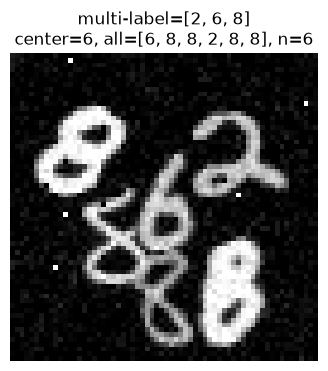

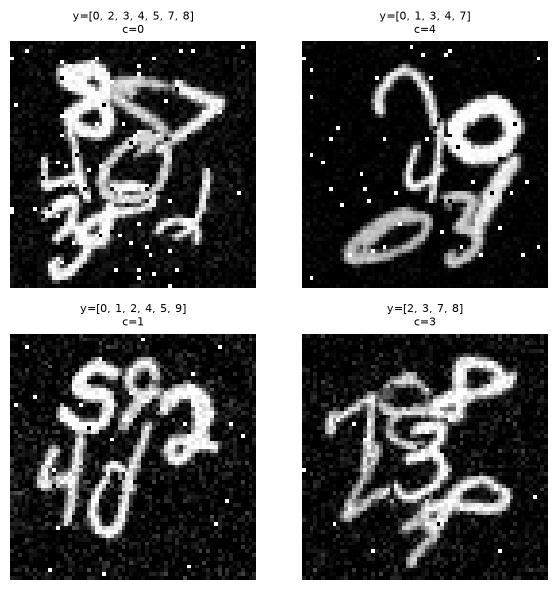

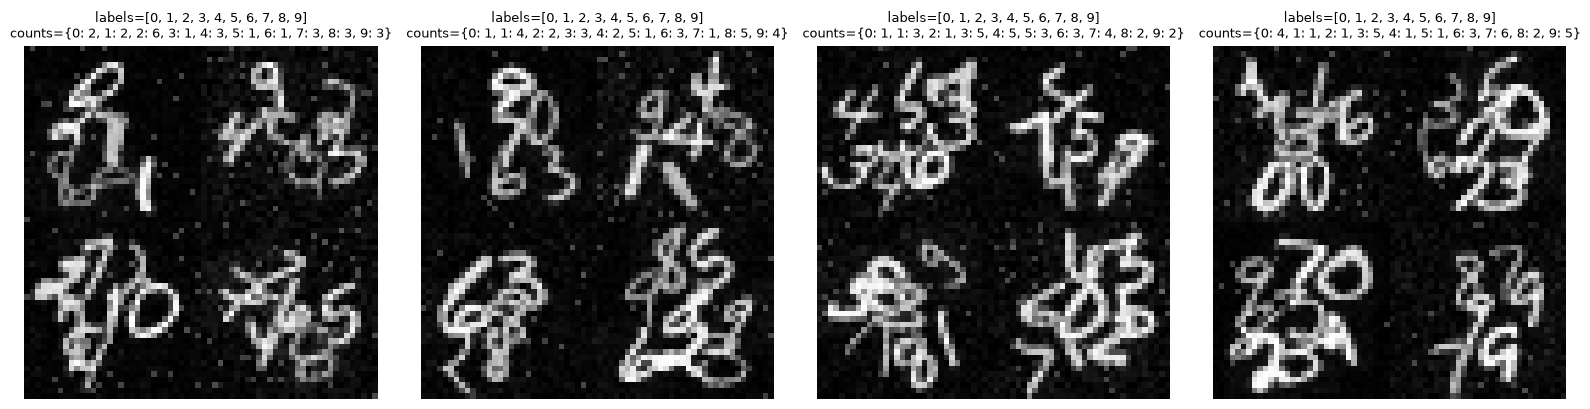

In [13]:
def multihot_to_digits(multihot):
    """
    Convert a multi-hot vector into a list of digit labels.

    Example:
        [0, 1, 0, 0, 1, 0, 0, 0, 0, 1]
        becomes
        [1, 4, 9]
    """
    return np.where(multihot >= 0.5)[0].tolist()


def visualize_one_sample(images, labels, meta, idx=0):
    """Visualize one generated image and its labels."""
    img = images[idx].squeeze()

    digits_present = multihot_to_digits(labels[idx])
    center_label = meta["center_labels"][idx]
    all_labels = meta["all_digit_labels"][idx]
    n_digits = meta["num_digits"][idx]

    # Remove padding values.
    valid_all_labels = all_labels[all_labels >= 0].tolist()

    plt.figure(figsize=(4, 4))
    plt.imshow(img, cmap="gray")
    plt.title(
        f"multi-label={digits_present}\n"
        f"center={center_label}, all={valid_all_labels}, n={n_digits}"
    )
    plt.axis("off")
    plt.show()


def visualize_grid(images, labels, meta, num_samples=16):
    """Visualize a grid of random samples."""
    rows = int(np.sqrt(num_samples))
    cols = int(np.ceil(num_samples / rows))

    plt.figure(figsize=(6, 6))

    for i in range(num_samples):
        idx = random.randint(0, len(images) - 1)

        img = images[idx].squeeze()
        digits_present = multihot_to_digits(labels[idx])
        center_label = meta["center_labels"][idx]

        plt.subplot(rows, cols, i + 1)
        plt.imshow(img, cmap="gray")
        plt.title(f"y={digits_present}\nc={center_label}", fontsize=8)
        plt.axis("off")

    plt.tight_layout()
    plt.show()


def visualize_mosaic_samples(images32, labels, histograms, num_samples=4, seed=SEED):
    """Display generated mosaics with multilabel and histogram targets."""
    rng = np.random.default_rng(seed)
    mosaic_images, mosaic_labels, mosaic_histograms = generate_mosaic_dataset(
        images32, labels, histograms, num_samples, rng
    )

    fig, axes = plt.subplots(1, num_samples, figsize=(4 * num_samples, 4))
    axes = np.atleast_1d(axes)
    for i, ax in enumerate(axes):
        ax.imshow(mosaic_images[i].squeeze(), cmap="gray")
        digits = np.where(mosaic_labels[i] >= 0.5)[0].tolist()
        counts = {d: int(c) for d, c in enumerate(mosaic_histograms[i]) if c > 0}
        ax.set_title(f"labels={digits}\ncounts={counts}", fontsize=9)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

# Visualize samples if the dataset has been loaded.
if "x_train" in globals():
    visualize_one_sample(x_train, y_train, meta_train, idx=0)
    visualize_grid(x_train, y_train, meta_train, num_samples=4)
    visualize_mosaic_samples(x_train_32, y_train, y_train_hist)

# 3. Define exact match accuracy metrics:

In [8]:
def exact_match_accuracy(y_true, y_pred):
    """
    Exact-match accuracy for multi-label classification.

    Steps:
    1. Convert predicted probabilities to binary labels using a threshold.
    2. Compare the whole predicted vector with the true vector.
    3. Count the sample as correct only if every label matches.

    This metric is strict but useful.
    """
    y_pred_binary = tf.cast(y_pred >= 0.5, tf.float32)

    # For each sample, check whether all 10 labels are correct.
    matches = tf.reduce_all(tf.equal(y_true, y_pred_binary), axis=1)

    return tf.reduce_mean(tf.cast(matches, tf.float32))

# 4. Build the ResNet-18 model

In [9]:
def basic_block(x, filters, stride=1, name=None):
    """A standard ResNet basic block with two 3x3 convolutions."""
    shortcut = x

    y = layers.Conv2D(
        filters,
        kernel_size=3,
        strides=stride,
        padding="same",
        use_bias=False,
        name=None if name is None else f"{name}_conv1",
    )(x)
    y = layers.BatchNormalization(name=None if name is None else f"{name}_bn1")(y)
    y = layers.ReLU(name=None if name is None else f"{name}_relu1")(y)

    y = layers.Conv2D(
        filters,
        kernel_size=3,
        strides=1,
        padding="same",
        use_bias=False,
        name=None if name is None else f"{name}_conv2",
    )(y)
    y = layers.BatchNormalization(name=None if name is None else f"{name}_bn2")(y)

    if stride != 1 or x.shape[-1] != filters:
        shortcut = layers.Conv2D(
            filters,
            kernel_size=1,
            strides=stride,
            padding="same",
            use_bias=False,
            name=None if name is None else f"{name}_proj_conv",
        )(shortcut)
        shortcut = layers.BatchNormalization(name=None if name is None else f"{name}_proj_bn")(shortcut)

    y = layers.Add(name=None if name is None else f"{name}_add")([shortcut, y])
    y = layers.ReLU(name=None if name is None else f"{name}_out_relu")(y)
    return y


def build_resnet18_model(input_shape=(64, 64, 3)):
    """Build a ResNet-18 from scratch for multi-task learning."""
    inputs = keras.Input(shape=input_shape)

    x = layers.Conv2D(
        64,
        kernel_size=7,
        strides=2,
        padding="same",
        use_bias=False,
        name="conv1",
    )(inputs)
    x = layers.BatchNormalization(name="bn_conv1")(x)
    x = layers.ReLU(name="conv1_relu")(x)
    x = layers.MaxPooling2D(pool_size=3, strides=2, padding="same", name="pool1")(x)

    # ResNet-18 stages: 2, 2, 2, 2 basic blocks.
    x = basic_block(x, 64, stride=1, name="conv2_block1")
    x = basic_block(x, 64, stride=1, name="conv2_block2")

    x = basic_block(x, 128, stride=2, name="conv3_block1")
    x = basic_block(x, 128, stride=1, name="conv3_block2")

    x = basic_block(x, 256, stride=2, name="conv4_block1")
    x = basic_block(x, 256, stride=1, name="conv4_block2")

    x = basic_block(x, 512, stride=2, name="conv5_block1")
    x = basic_block(x, 512, stride=1, name="conv5_block2")

    x = layers.GlobalAveragePooling2D(name="avg_pool")(x)
    x = layers.Dense(512, activation="relu", name="fc1")(x)
    x = layers.Dropout(0.5, name="dropout")(x)

    multilabel_output = layers.Dense(10, activation="sigmoid", name="multilabel_output")(x)
    histogram_output = layers.Dense(10, activation="linear", name="histogram_output")(x)

    return keras.Model(
        inputs=inputs,
        outputs={"multilabel_output": multilabel_output, "histogram_output": histogram_output},
        name="multi_task_resnet18",
    )


In [10]:
# Build the model
INPUT_SHAPE = (64, 64, 3)
model = build_resnet18_model(input_shape=INPUT_SHAPE)

In [ ]:
# Compile the model with separate losses and metrics for each output.
model.compile(
    optimizer=keras.optimizers.SGD(
        learning_rate=0.05,
        momentum=0.9,
        use_ema=True,
        weight_decay=3e-2
    ),
    loss={
        "multilabel_output": keras.losses.BinaryCrossentropy(),
        "histogram_output": keras.losses.MeanSquaredError(),
    },
    loss_weights={
        "multilabel_output": 0.5,
        "histogram_output": 0.5,
    },
    metrics={
        "multilabel_output": [
            keras.metrics.BinaryAccuracy(name="binary_accuracy"),
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
            keras.metrics.MeanMetricWrapper(exact_match_accuracy, name="exact_match_accuracy"),
        ],
        "histogram_output": [
            keras.metrics.MeanAbsoluteError(name="mae"),
        ],
    },
)


In [12]:
class MultiTaskTrainingLogger(keras.callbacks.Callback):
    """Print a compact epoch summary for the two-task training run."""

    def on_train_begin(self, logs=None):
        self.total_epochs = self.params.get("epochs", 0)

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}

        def get_value(key):
            value = logs.get(key, float("nan"))
            return float(value)

        lr = self.model.optimizer.learning_rate
        if hasattr(lr, "numpy"):
            lr = float(lr.numpy())
        else:
            lr = float(tf.keras.backend.get_value(lr))
            
        print("=" * 50)
        print(f"Epoch {epoch + 1}/{self.total_epochs}")
        print("=" * 50)
        print()
        print("Train")
        print(f"  Exact Match  : {get_value('multilabel_output_exact_match_accuracy'):.4f}")
        print(f"  Loss         : {get_value('multilabel_output_loss'):.4f}")
        print(f"  Precision    : {get_value('multilabel_output_precision'):.4f}")
        print(f"  Recall       : {get_value('multilabel_output_recall'):.4f}")
        print()
        print("Validation")
        print(f"  Exact Match  : {get_value('val_multilabel_output_exact_match_accuracy'):.4f}")
        print(f"  Loss         : {get_value('val_multilabel_output_loss'):.4f}")
        print(f"  Precision    : {get_value('val_multilabel_output_precision'):.4f}")
        print(f"  Recall       : {get_value('val_multilabel_output_recall'):.4f}")
        print()
        print("Histogram")
        print(f"  Train Loss: {get_value('histogram_output_loss'):.4f} ")
        print(f"  Val Loss: {get_value('val_histogram_output_loss'):.4f} ")
        print()
        print(f"Learning Rate : {lr:.4f}")
        print()


In [13]:
# Display the model architecture.
model.summary()

Model: "multi_task_resnet18"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 64, 64, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1 (Conv2D)      │ (None, 32, 32,    │      9,408 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_conv1            │ (None, 32, 32,    │        256 │ conv1[0][0]       │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu (ReLU)   │ (None, 32, 32,    │          0 │ bn_conv1[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 16, 16,    │          0 │ conv1_relu[0][0]  │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_conv1  │ (None, 16, 16,    │     36,864 │ pool1[0][0]       │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_bn1    │ (None, 16, 16,    │        256 │ conv2_block1_con… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_relu1  │ (None, 16, 16,    │          0 │ conv2_block1_bn1… │
│ (ReLU)              │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_conv2  │ (None, 16, 16,    │     36,864 │ conv2_block1_rel… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_bn2    │ (None, 16, 16,    │        256 │ conv2_block1_con… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_add    │ (None, 16, 16,    │          0 │ pool1[0][0],      │
│ (Add)               │ 64)               │            │ conv2_block1_bn2… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_out_r… │ (None, 16, 16,    │          0 │ conv2_block1_add… │
│ (ReLU)              │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_conv1  │ (None, 16, 16,    │     36,864 │ conv2_block1_out… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_bn1    │ (None, 16, 16,    │        256 │ conv2_block2_con… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_relu1  │ (None, 16, 16,    │          0 │ conv2_block2_bn1… │
│ (ReLU)              │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_conv2  │ (None, 16, 16,    │     36,864 │ conv2_block2_rel… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_bn2    │ (None, 16, 16,    │        256 │ conv2_block2_con

 Total params: 11,459,028 (43.71 MB)

 Trainable params: 11,449,428 (43.68 MB)

 Non-trainable params: 9,600 (37.50 KB)

# 5. Train the model

In [ ]:
# Training hyperparameters.
BATCH_SIZE = 64
EPOCHS = 200

CLOSE_MOSAIC_EPOCH = 0
MOSAIC_RATIO = 0.1

class DynamicMosaicSequence(keras.utils.Sequence):
    """Serve originals plus fresh mosaics during early epochs."""
    def __init__(self, images,images32, labels, histograms, batch_size, close_epoch, mosaic_ratio, seed=SEED):
        super().__init__()
        self.images = images
        self.images32 = images32
        self.labels = labels
        self.histograms = histograms
        self.batch_size = batch_size
        self.close_epoch = close_epoch
        self.num_mosaics = max(1, int(len(images) * mosaic_ratio))
        self.rng = np.random.default_rng(seed)
        self.max_samples = len(images) + self.num_mosaics
        self.current_images = images
        self.current_labels = labels
        self.current_histograms = histograms
        self.use_mosaic = False
        self.current_epoch = None

    def set_epoch(self, epoch):
        if self.current_epoch == epoch:
            return
        self.use_mosaic = epoch < self.close_epoch
        if self.use_mosaic:
            print(f"Generating {self.num_mosaics} mosaics for epoch {epoch + 1}")
            mosaic_images, mosaic_labels, mosaic_histograms = generate_mosaic_dataset(
                self.images32, self.labels, self.histograms, self.num_mosaics, self.rng
            )
            self.current_images = np.concatenate([self.images, mosaic_images], axis=0)
            self.current_labels = np.concatenate([self.labels, mosaic_labels], axis=0)
            self.current_histograms = np.concatenate([self.histograms, mosaic_histograms], axis=0)
            
            perm = self.rng.permutation(len(self.current_images))
            self.current_images = self.current_images[perm]
            self.current_labels = self.current_labels[perm]
            self.current_histograms = self.current_histograms[perm]
        else:
            self.current_images = self.images
            self.current_labels = self.labels
            self.current_histograms = self.histograms
        self.current_epoch = epoch

    def __len__(self):
        return int(np.ceil(len(self.current_images) / self.batch_size))

    def __getitem__(self, batch_index):
        start = batch_index * self.batch_size
        end = min(start + self.batch_size, len(self.current_images))
        indices = np.arange(start, end)
        return self.current_images[indices], {
            "multilabel_output": self.current_labels[indices],
            "histogram_output": self.current_histograms[indices],
        }

class MosaicEpochScheduler(keras.callbacks.Callback):
    def __init__(self, sequence):
        super().__init__()
        self.sequence = sequence

    def on_epoch_begin(self, epoch, logs=None):
        self.sequence.set_epoch(epoch)

train_sequence = DynamicMosaicSequence(
    x_train, x_train_32, y_train, y_train_hist, BATCH_SIZE,
    CLOSE_MOSAIC_EPOCH, MOSAIC_RATIO,
)

# Use callbacks to improve training.
callbacks = [
    MosaicEpochScheduler(train_sequence),
    MultiTaskTrainingLogger(),
    keras.callbacks.EarlyStopping(
        monitor="val_multilabel_output_exact_match_accuracy",
        mode="max",
        patience=20,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.25,
        patience=10,
        min_lr=1e-5,
        verbose=1
    ),
]


In [ ]:
# Train the model.
history = model.fit(
    train_sequence,
    validation_data=(
        x_val,
        {
            "multilabel_output": y_val,
            "histogram_output": y_val_hist,
        },
    ),
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=0,
)


Generating 12500 mosaics for epoch 1


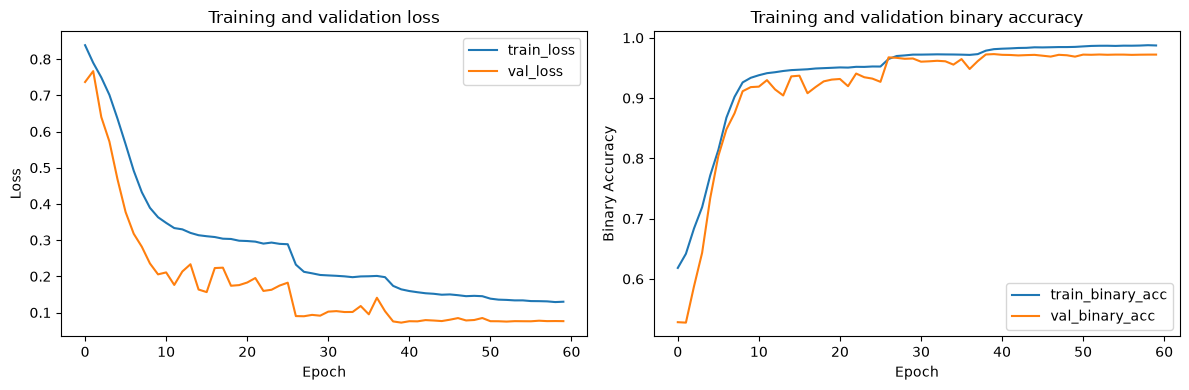

In [ ]:
# Plot training history if available.

if "history" in globals():
    plt.figure(figsize=(12, 4))

    # Loss curve.
    plt.subplot(1, 2, 1)
    plt.plot(history.history["loss"], label="train_loss")
    plt.plot(history.history["val_loss"], label="val_loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Training and validation loss")
    plt.legend()

    # Binary accuracy curve.
    plt.subplot(1, 2, 2)
    plt.plot(history.history["multilabel_output_binary_accuracy"], label="train_binary_acc")
    plt.plot(history.history["val_multilabel_output_binary_accuracy"], label="val_binary_acc")
    plt.xlabel("Epoch")
    plt.ylabel("Binary Accuracy")
    plt.title("Training and validation binary accuracy")
    plt.legend()

    plt.tight_layout()
    plt.show()
else:
    print("No training history found.")

## Evaluation Notes
- The primary metric remains `val_multilabel_output_exact_match_accuracy`.
- The histogram head is auxiliary and uses a smaller loss weight.


In [ ]:
# Evaluate the model on the test set.
results = model.evaluate(
    x_test,
    {
        "multilabel_output": y_test,
        "histogram_output": y_test_hist,
    },
    verbose=1,
)

# print("\\nTest results:")
# for name, value in zip(model.metrics_names, results):
#     print(f"{name}: {value:.4f}")


111/313 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - histogram_output_loss: 0.0486 - histogram_output_mae: 0.1198 - loss: 0.0708 - multilabel_output_binary_accuracy: 0.9744 - multilabel_output_exact_match_accuracy: 0.8094 - multilabel_output_loss: 0.0929 - multilabel_output_precision: 0.9774 - multilabel_output_recall: 0.9731

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - histogram_output_loss: 0.0481 - histogram_output_mae: 0.1192 - loss: 0.0704 - multilabel_output_binary_accuracy: 0.9737 - multilabel_output_exact_match_accuracy: 0.8047 - multilabel_output_loss: 0.0927 - multilabel_output_precision: 0.9765 - multilabel_output_recall: 0.9730


# 7. Visualize predictions

The model outputs probabilities.

Example:

```text
digit 0: 0.02
digit 1: 0.91
digit 2: 0.04
...
```

If a probability is greater than or equal to the threshold, that digit is predicted as present.

In [ ]:
# Prediction helper functions
# Student donnt allow to change the threshold value
PREDICTION_THRESHOLD=0.5
def probs_to_digits(probs, threshold=PREDICTION_THRESHOLD):
    """Convert prediction probabilities into a list of predicted digits."""
    return np.where(probs >= threshold)[0].tolist()

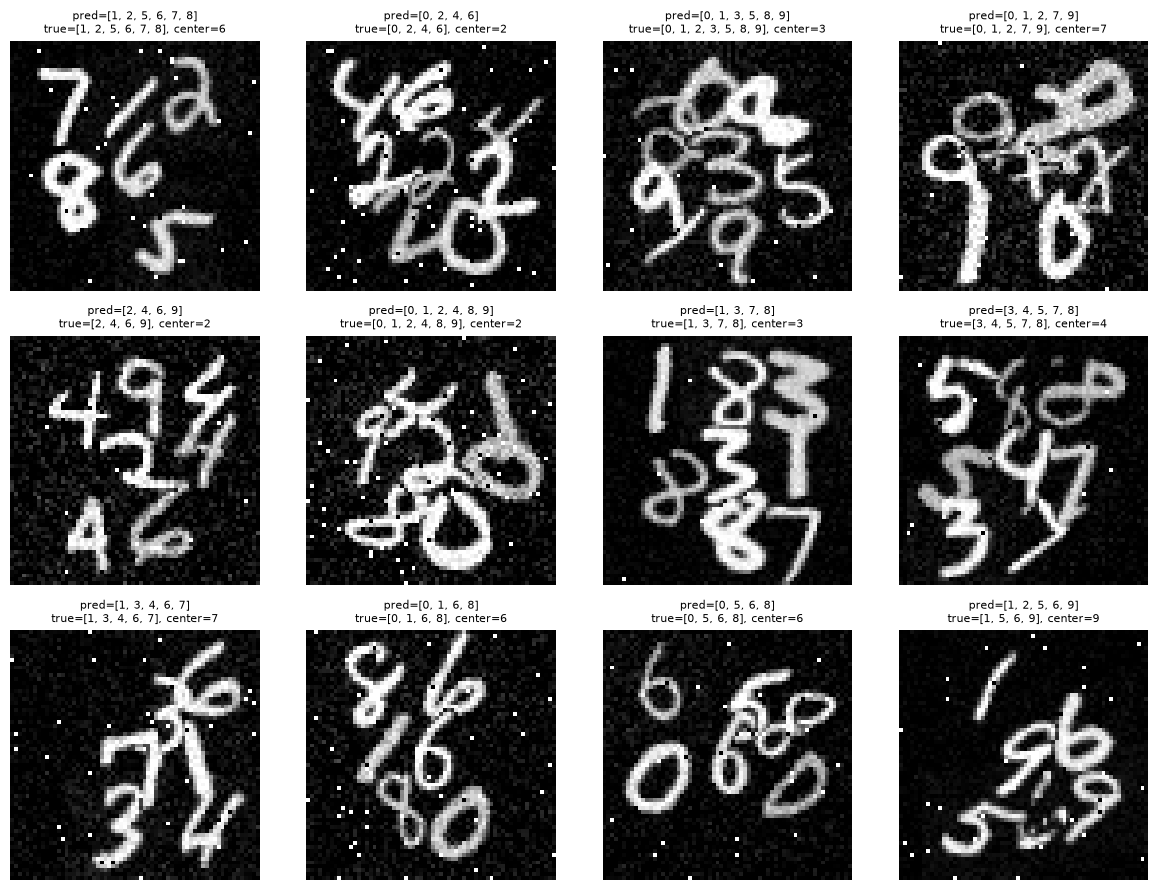

In [ ]:

# Visualize several test predictions.

if "model" in globals() and "x_test" in globals():
    indices = np.random.choice(len(x_test), size=12, replace=False)
    preds = model.predict(x_test[indices], verbose=0)
    probs = preds["multilabel_output"]

    plt.figure(figsize=(12, 9))

    for i, idx in enumerate(indices):
        true_digits = multihot_to_digits(y_test[idx])
        pred_digits = probs_to_digits(probs[i], threshold=PREDICTION_THRESHOLD)
        center_label = meta_test["center_labels"][idx]

        plt.subplot(3, 4, i + 1)
        plt.imshow(x_test[idx].squeeze(), cmap="gray")
        plt.title(
            f"pred={pred_digits}\n"
            f"true={true_digits}, center={center_label}",
            fontsize=8,
        )
        plt.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("Model or test data not available.")

In [ ]:

# Inspect one test prediction in detail.
idx = 0
preds = model.predict(x_test[idx:idx + 1], verbose=0)
prob = preds["multilabel_output"][0]

print("True digits:", multihot_to_digits(y_test[idx]))
print("Predicted digits:", probs_to_digits(prob))
print("Center label:", meta_test["center_labels"][idx])
print()

print("Prediction probabilities:")
for digit, p in enumerate(prob):
    print(f"digit {digit}: {p:.4f}")

True digits: [2, 3, 5, 7, 9]
Predicted digits: [2, 3, 5, 7, 9]
Center label: 7

Prediction probabilities:
digit 0: 0.0149
digit 1: 0.0184
digit 2: 0.9915
digit 3: 0.9955
digit 4: 0.0350
digit 5: 0.9923
digit 6: 0.0285
digit 7: 1.0000
digit 8: 0.0276
digit 9: 0.9919


: 

In [ ]:
# Exit kernel
import os
os.kill(os.getpid(), 9)